In [ ]:
%pip install seaborn
%pip install matplotlib

In [81]:
import os, sys
project_root = os.path.abspath("..")
sys.path.append(project_root)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

sns.set_style("whitegrid")

from helpers import *

In [69]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1998 entries, 0 to 1997
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Gender                    1998 non-null   int64
 1   Age                       1998 non-null   int64
 2   Education_Level           1998 non-null   int64
 3   Employment_Status         1998 non-null   int64
 4   Depression_Type           1998 non-null   int64
 5   Symptoms                  1998 non-null   int64
 6   Low_Energy                1998 non-null   int64
 7   Low_SelfEsteem            1998 non-null   int64
 8   Search_Depression_Online  1998 non-null   int64
 9   Worsening_Depression      1998 non-null   int64
 10  Your overeating level     1998 non-null   int64
 11  How many times you eat    1998 non-null   int64
 12  SocialMedia_Hours         1998 non-null   int64
 13  SocialMedia_WhileEating   1998 non-null   int64
 14  Sleep_Hours               1998 non-null   int64
 15

In [38]:
df.isna().sum().sum()

np.int64(0)

In [39]:
df.duplicated().sum()

np.int64(0)

In [40]:
df.describe()

,Gender,Age,Education_Level,Employment_Status,Depression_Type,Symptoms,Low_Energy,Low_SelfEsteem,Search_Depression_Online,Worsening_Depression,...,How many times you eat,SocialMedia_Hours,SocialMedia_WhileEating,Sleep_Hours,Nervous_Level,Depression_Score,Coping_Methods,Self_Harm,Mental_Health_Support,Suicide_Attempts
count,1998.000000,1998.000000,1998.000000,1998.000000,1998.000000,1998.000000,1998.000000,1998.000000,1998.000000,1998.000000,...,1998.000000,1998.000000,1998.000000,1998.000000,1998.000000,1998.000000,1998.000000,1998.000000,1998.000000,1998.000000
mean,0.514014,24.261762,1.869369,2.097097,5.673173,6.553053,0.709710,0.696196,0.386887,0.652152,...,0.204705,5.960961,2.063564,6.505506,5.702202,14.622623,5.920420,0.098098,0.224725,1.434434
std,0.499929,7.928578,0.472003,0.873915,2.935595,3.852428,0.485973,0.488522,0.487159,0.476407,...,0.403587,3.728180,0.992946,2.278048,2.504859,8.948343,4.092346,0.297522,0.417505,1.135513
min,0.000000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,3.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,25.000000,2.000000,2.000000,2.000000,5.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,3.000000,2.000000,5.000000,4.000000,7.000000,2.000000,0.000000,0.000000,0.000000
50%,1.000000,25.000000,2.000000,2.000000,5.000000,5.000000,1.000000,1.000000,0.000000,1.000000,...,0.000000,6.000000,2.000000,7.000000,5.000000,14.000000,6.000000,0.000000,0.000000,1.000000
75%,1.000000,25.000000,2.000000,2.000000,9.000000,9.000000,1.000000,1.000000,1.000000,1.000000,...,0.000000,9.000000,3.000000,8.000000,8.000000,22.000000,9.000000,0.000000,0.000000,2.000000
max,1.000000,35.000000,3.000000,4.000000,11.000000,14.000000,2.000000,2.000000,1.000000,1.000000,...,1.000000,12.000000,3.000000,10.000000,10.000000,30.000000,13.000000,1.000000,1.000000,3.000000


In [41]:
df.sample(5)

,Gender,Age,Education_Level,Employment_Status,Depression_Type,Symptoms,Low_Energy,Low_SelfEsteem,Search_Depression_Online,Worsening_Depression,...,How many times you eat,SocialMedia_Hours,SocialMedia_WhileEating,Sleep_Hours,Nervous_Level,Depression_Score,Coping_Methods,Self_Harm,Mental_Health_Support,Suicide_Attempts
1379,0,35,2,2,2,13,1,0,0,1,...,0,7,3,10,7,5,9,1,1,2
1088,0,25,2,2,6,5,1,1,0,1,...,0,1,3,4,7,13,11,1,0,0
686,0,35,1,3,7,10,0,0,0,0,...,0,3,2,10,3,19,7,0,1,1
1100,0,25,2,2,0,1,1,1,0,1,...,1,8,3,8,10,23,9,0,0,1
1170,0,25,2,2,5,0,1,1,0,1,...,0,1,3,9,10,4,0,0,1,2


In [70]:
label_maps = {
    'Gender': {0: 'Male', 1: 'Female'},
    'Age': {10: 'Childhood', 25: 'Youth', 35: 'Maturity'},
    'Education_Level': {0: 'Primary or Below', 1: 'High school', 2: 'Undergraduate', 3: 'Postgraduate'},
    'Employment_Status': {0: 'Unemployed', 1: 'Student', 2: 'Employed', 3: 'Self-employed', 4: 'Other'},

    'SocialMedia_WhileEating': {0: 'Never', 1: 'Rarely', 2: 'Sometimes', 3: 'Always'},
    'How many times you eat ': {0: '≤2 meals', 1: '3 meals'},
    'Search_Depression_Online': {0: 'No', 1: 'Yes'},
    'Mental_Health_Support': {0: 'No Support', 1: 'Received Support'},

    'Low_Energy': {0: 'No', 1: 'Yes', 2: 'Occasionally'},
    'Low_SelfEsteem': {0: 'No', 1: 'Yes', 2: 'Occasionally'},
    'Worsening_Depression': {0: 'No', 1: 'Yes'},
    'Self_Harm': {0: 'No history', 1: 'History of self-harm'},
    'Suicide_Attempts': {0: 'None', 1: 'Once', 2: 'Twice', 3: 'Three or more'}
}

In [71]:
groups = {
    "Demographic Features": [
        'Gender', 'Age', 'Education_Level', 'Employment_Status'
    ],

    "Behavioral Features": [
        'SocialMedia_Hours', 'SocialMedia_WhileEating', 'How many times you eat ',
        'Your overeating level', 'Sleep_Hours', 'Search_Depression_Online',
        'Mental_Health_Support', 'Coping_Methods'
    ],

    "Psychological Features": [
        'Symptoms', 'Low_Energy', 'Low_SelfEsteem', 'Worsening_Depression',
        'Nervous_Level', 'Depression_Score', 'Self_Harm', 'Suicide_Attempts'
    ]
}

In [72]:
pie_cols = [
    'Gender',
    'How many times you eat ',
    'Search_Depression_Online',
    'Mental_Health_Support'
]

line_cols = [
    'SocialMedia_Hours',
    'Sleep_Hours',
    'Nervous_Level',
    'Depression_Score'
]

vertical_bar_cols = [
    'Age',
    'Low_Energy',
    'Low_SelfEsteem',
    'Worsening_Depression',
    'Self_Harm',
    'Suicide_Attempts'
]

In [73]:
def get_counts_and_labels(col):
    if col == 'Your overeating level':
        grouped = df[col].replace({
            0: 'None',
            1: 'Mild', 2: 'Mild', 3: 'Mild', 4: 'Mild',
            5: 'Moderate', 6: 'Moderate', 7: 'Moderate', 8: 'Moderate',
            9: 'Severe', 10: 'Severe', 11: 'Severe', 12: 'Severe'
        })
        vc = grouped.value_counts().reindex(['None', 'Mild', 'Moderate', 'Severe'])
        labels = vc.index.astype(str)

    else:
        vc = df[col].value_counts().sort_index()
        labels = [label_maps[col].get(x, str(x)) for x in vc.index] if col in label_maps else vc.index.astype(str)

    return vc, labels

In [74]:
def plot_group(group_name, cols, ncols=3):
    nrows = math.ceil(len(cols) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(20, 5 * nrows))
    axes = axes.flatten()

    for i, col in enumerate(cols):
        vc, labels = get_counts_and_labels(col)
        ax = axes[i]

        if col in pie_cols:
            ax.pie(vc.values, labels=labels, autopct='%1.1f%%', startangle=90)

        elif col in line_cols:
            sns.lineplot(x=vc.index, y=vc.values, marker='o', ax=ax)
            ax.set_xlabel(col)
            ax.set_ylabel("Count")

        elif col in vertical_bar_cols:
            sns.barplot(x=labels, y=vc.values, ax=ax)
            ax.set_xlabel("")
            ax.set_ylabel("Count")
            ax.tick_params(axis='x', rotation=30)

        else:
            sns.barplot(x=vc.values, y=labels, ax=ax)
            ax.set_xlabel("Count")
            ax.set_ylabel("")

        ax.set_title(col, fontsize=12, fontweight='bold')

        for container in ax.containers:
            ax.bar_label(container, padding=3, fontsize=8)

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    fig.suptitle(group_name, fontsize=18, fontweight='bold')
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()


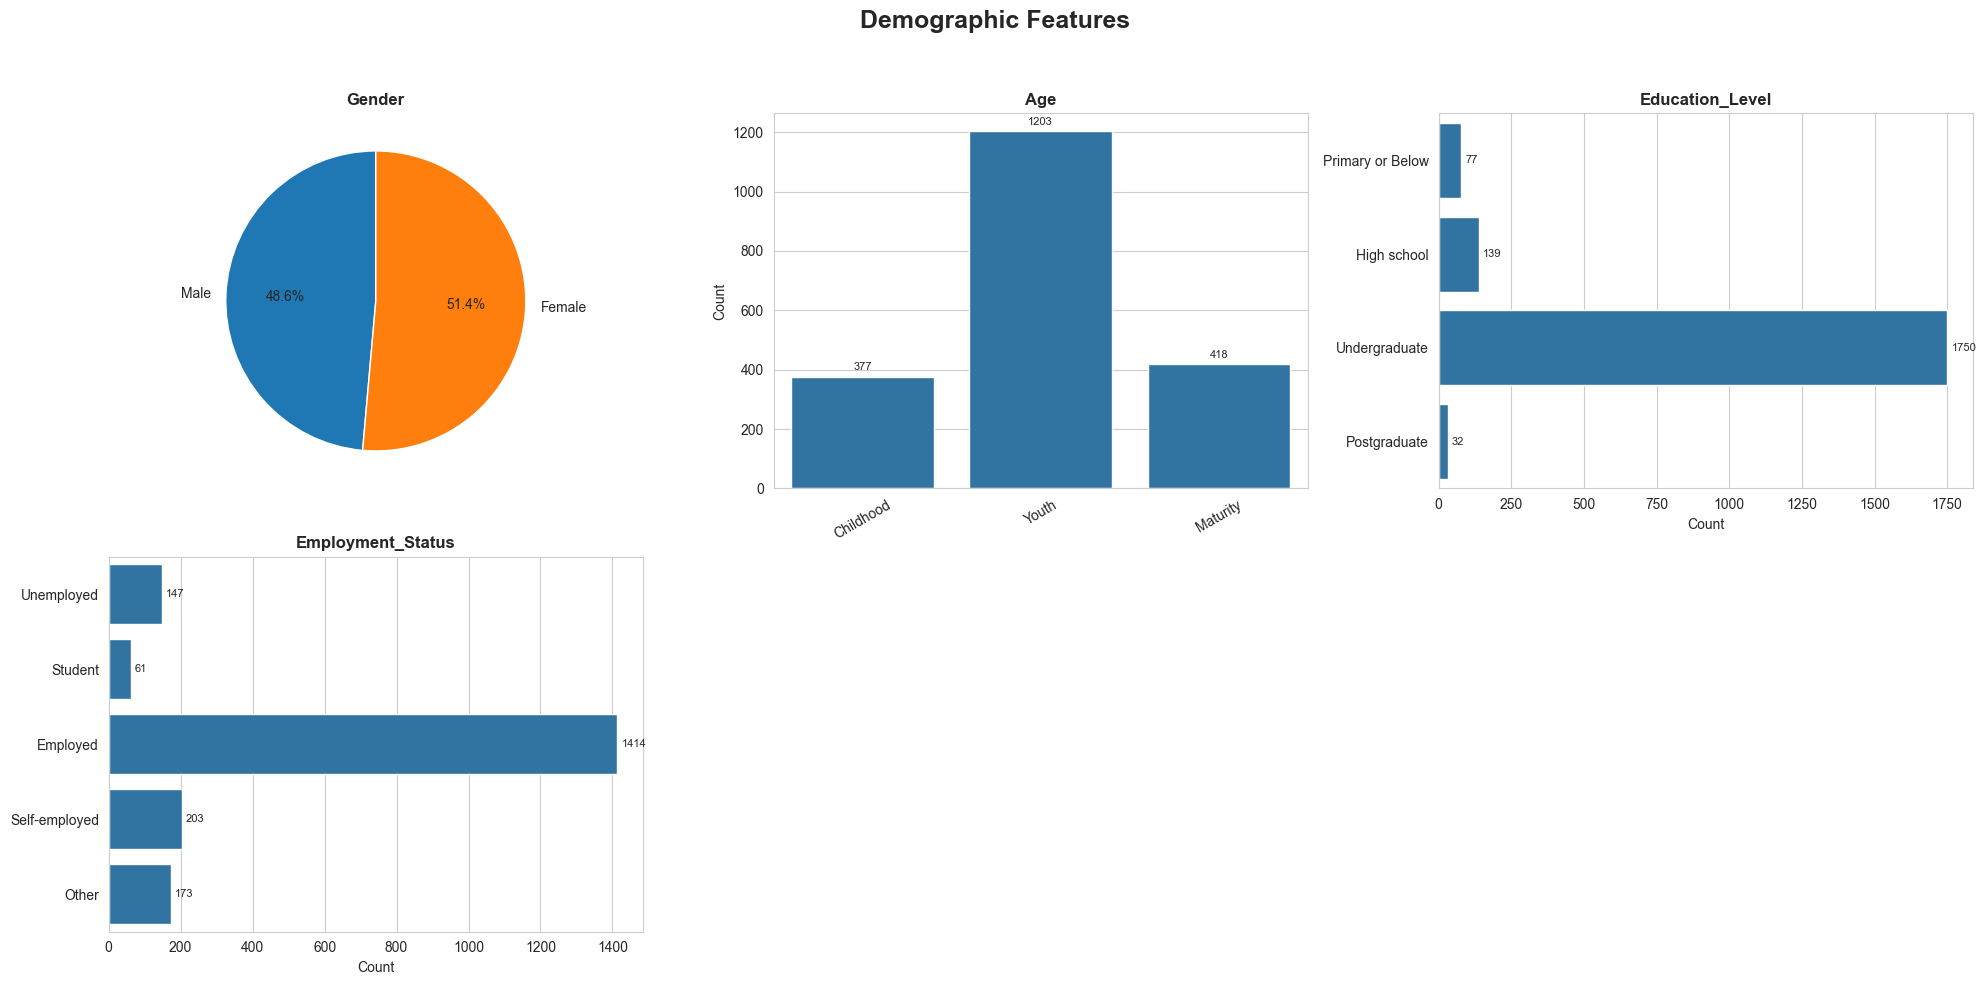

In [76]:
plot_group("Demographic Features", groups["Demographic Features"])

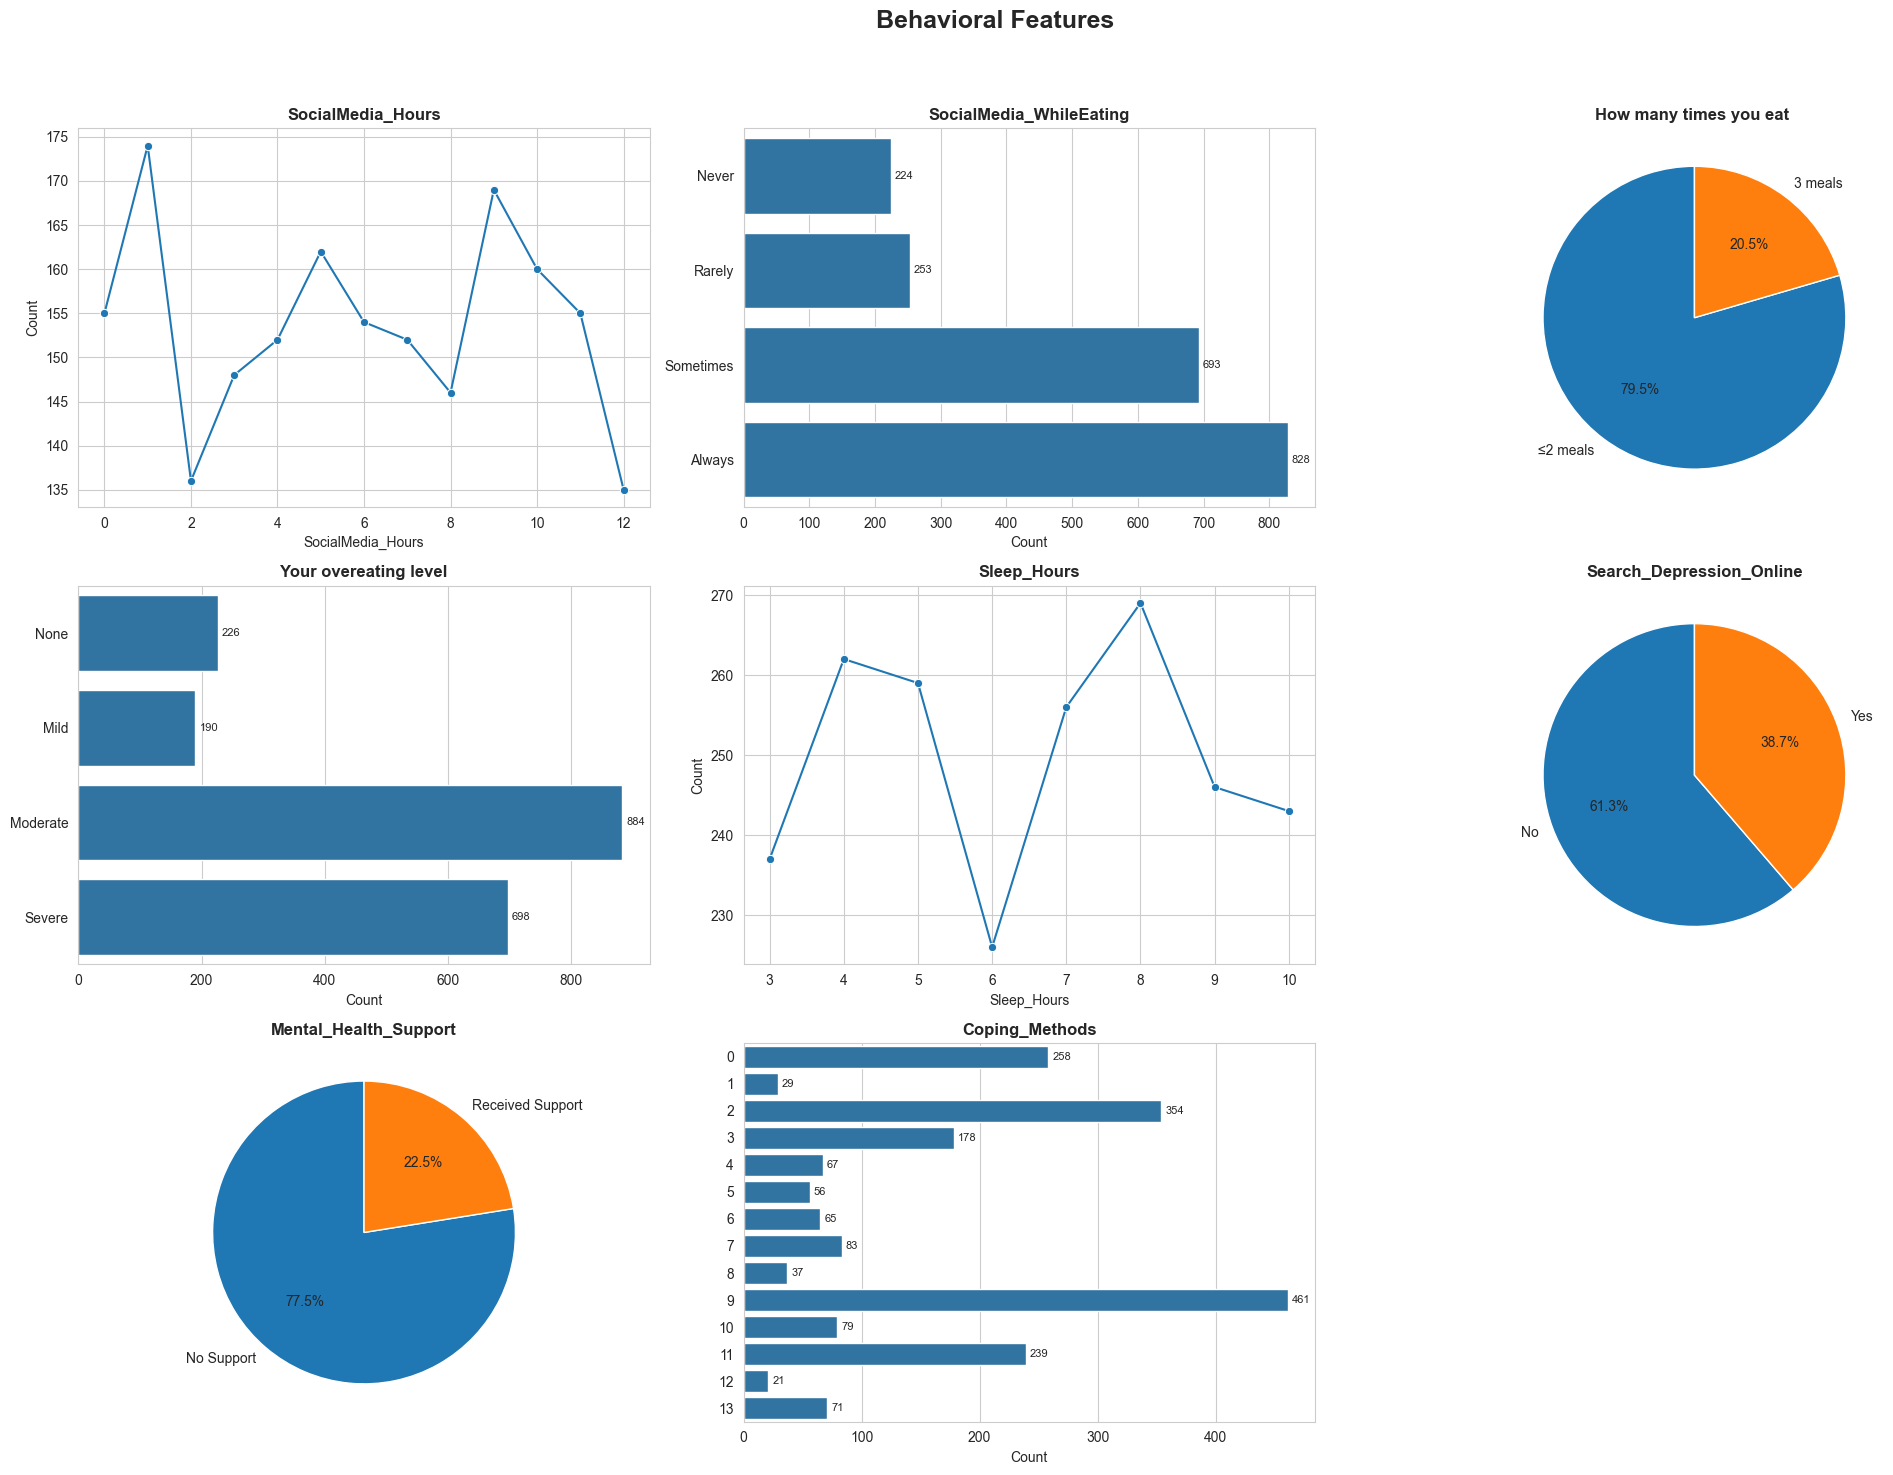

In [77]:
plot_group("Behavioral Features", groups["Behavioral Features"])

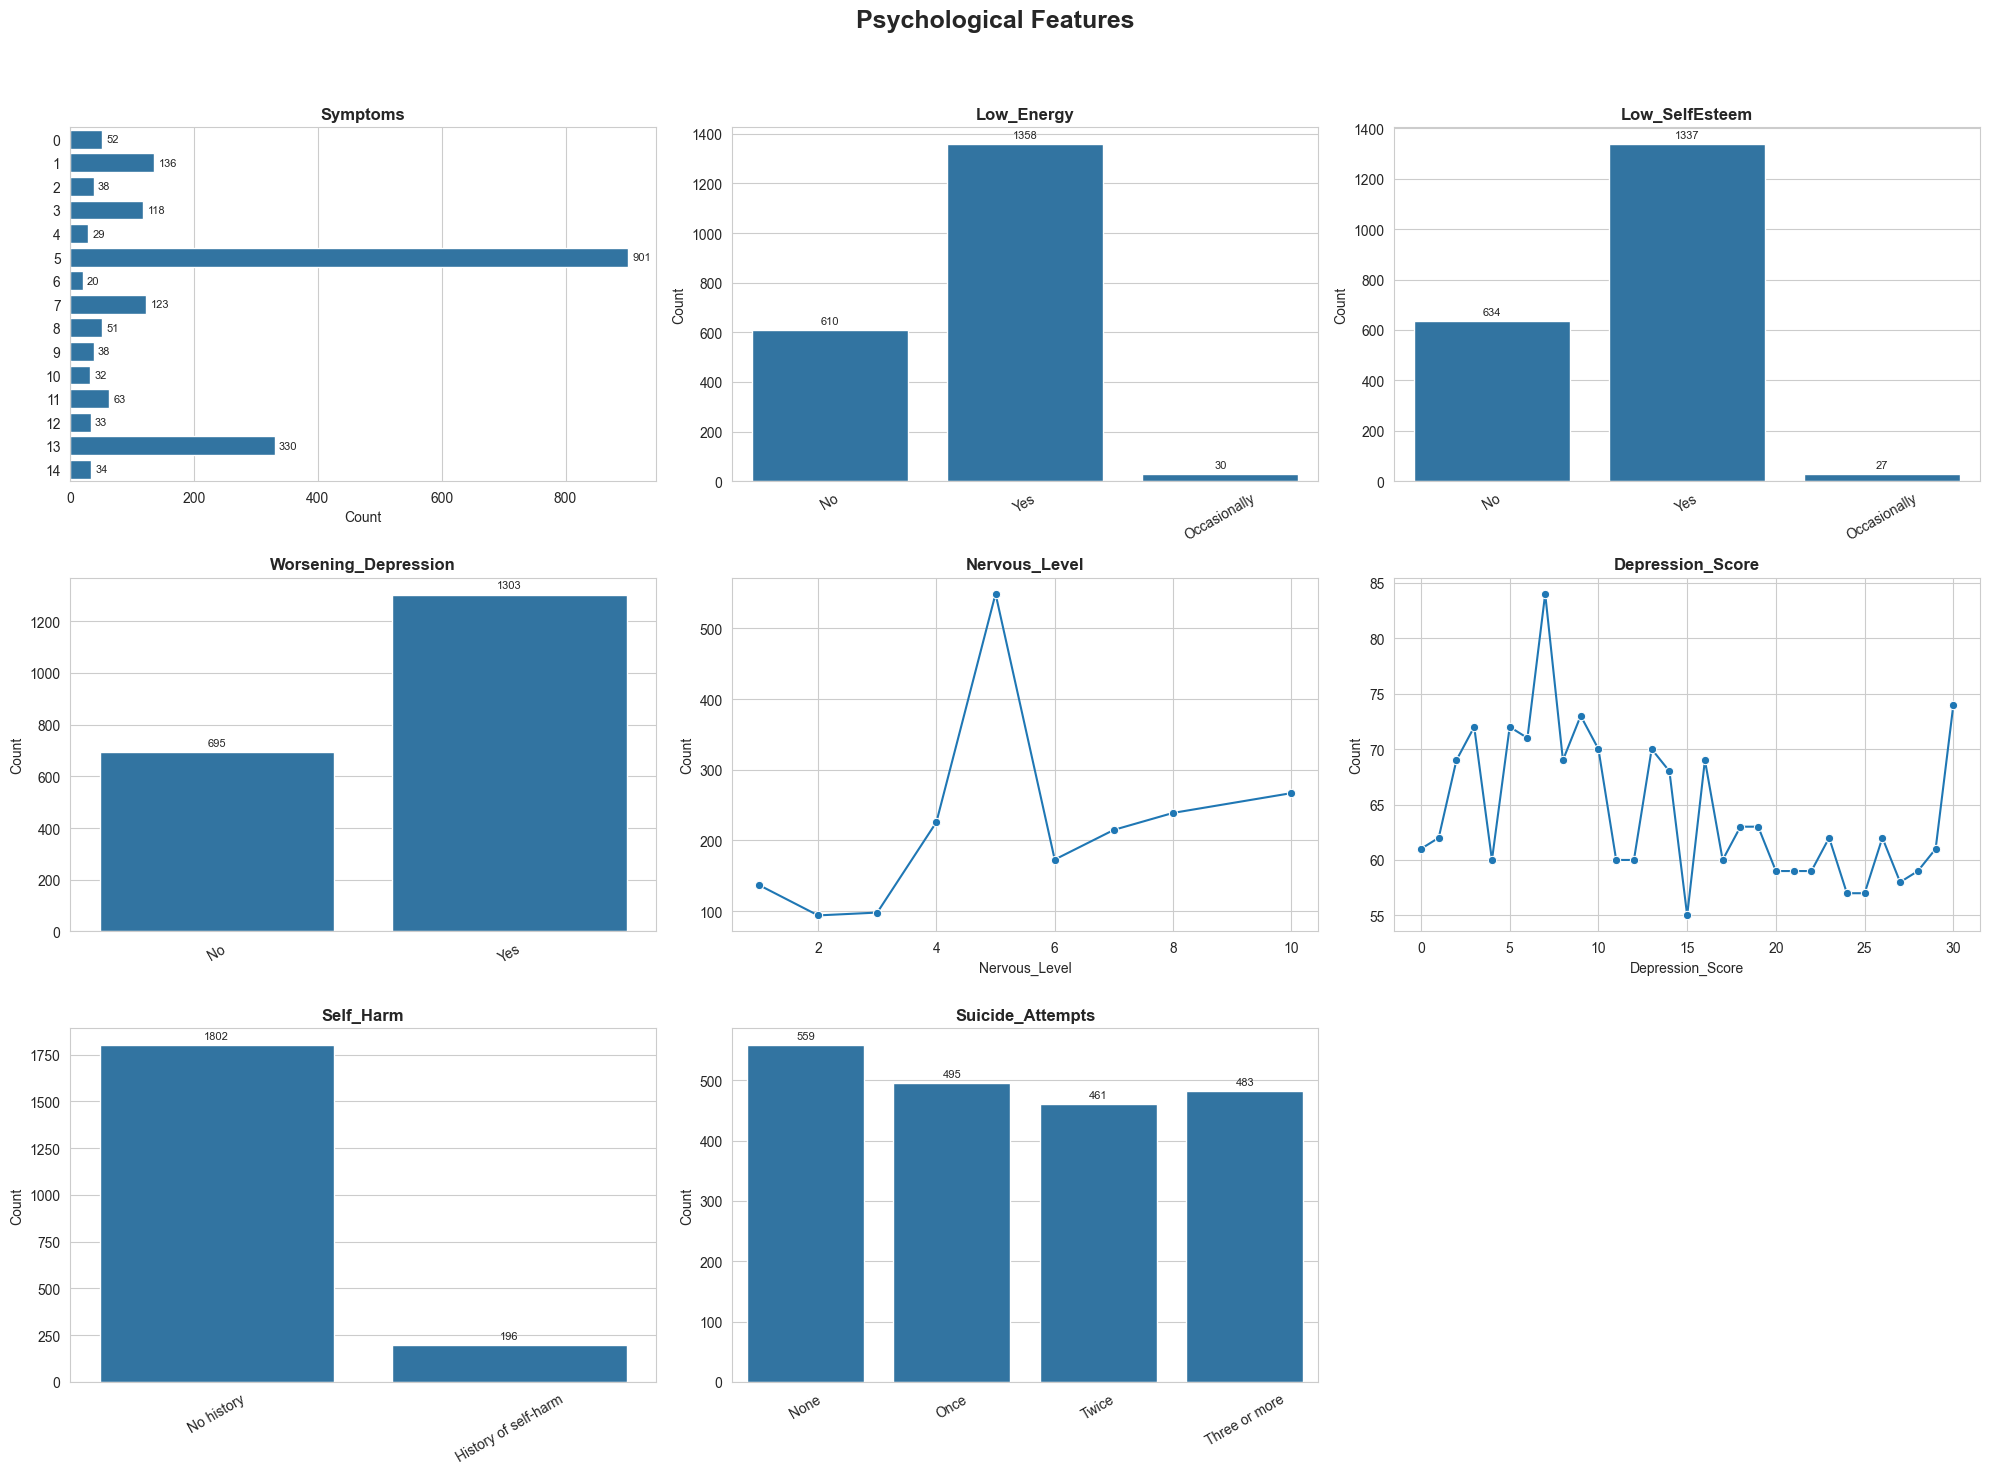

In [78]:
plot_group("Psychological Features", groups["Psychological Features"])